## Step 1: Data Preparation 

# Lab 4: Regression Analysis with Regularization Techniques

**Name:** Nikhil  
**Course:** MSCS-634  
**Lab Assignment:** Lab 4 – Regression Analysis with Regularization Techniques

In [1]:
from sklearn.datasets import load_diabetes
import pandas as pd
import matplotlib.pyplot as plt

diabetes = load_diabetes()

X = pd.DataFrame(
    diabetes.data,
    columns=diabetes.feature_names
)

y = pd.Series(
    diabetes.target,
    name="target"
)

print("Dataset loaded successfully.")
print("Features:", diabetes.feature_names)
print("Dataset shape:", X.shape)

Dataset loaded successfully.
Features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Dataset shape: (442, 10)


In [2]:
print("Feature names:")
print(X.columns.tolist())

print("\nFirst 10 rows:")
display(X.head(10))

Feature names:
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

First 10 rows:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641
5,-0.092695,-0.044642,-0.040696,-0.019442,-0.068991,-0.079288,0.041277,-0.076395,-0.041176,-0.096346
6,-0.045472,0.050680,-0.047163,-0.015999,-0.040096,-0.024800,0.000779,-0.039493,-0.062917,-0.038357
7,0.063504,0.050680,-0.001895,0.066629,0.090620,0.108914,0.022869,0.017703,-0.035816,0.003064
8,0.041708,0.050680,0.061696,-0.040099,-0.013953,0.006202,-0.028674,-0.002592,-0.014960,0.011349
9,-0.070900,-0.044642,0.039062,-0.033213,-0.012577,-0.034508,-0.024993,-0.002592,0.067737,-0.013504


In [3]:
print("First 10 target values:")
print(y.head(10))

print("\nTarget statistics:")
display(y.describe())

First 10 target values:
0    151.0
1     75.0
2    141.0
3    206.0
4    135.0
5     97.0
6    138.0
7     63.0
8    110.0
9    310.0
Name: target, dtype: float64

Target statistics:


count    442.000000
mean     152.133484
std       77.093005
min       25.000000
25%       87.000000
50%      140.500000
75%      211.500000
max      346.000000
Name: target, dtype: float64

In [4]:
print("Missing values in each feature:")
print(X.isnull().sum())

print("\nTotal missing values:")
print(X.isnull().sum().sum())

Missing values in each feature:
age    0
sex    0
bmi    0
bp     0
s1     0
s2     0
s3     0
s4     0
s5     0
s6     0
dtype: int64

Total missing values:
0


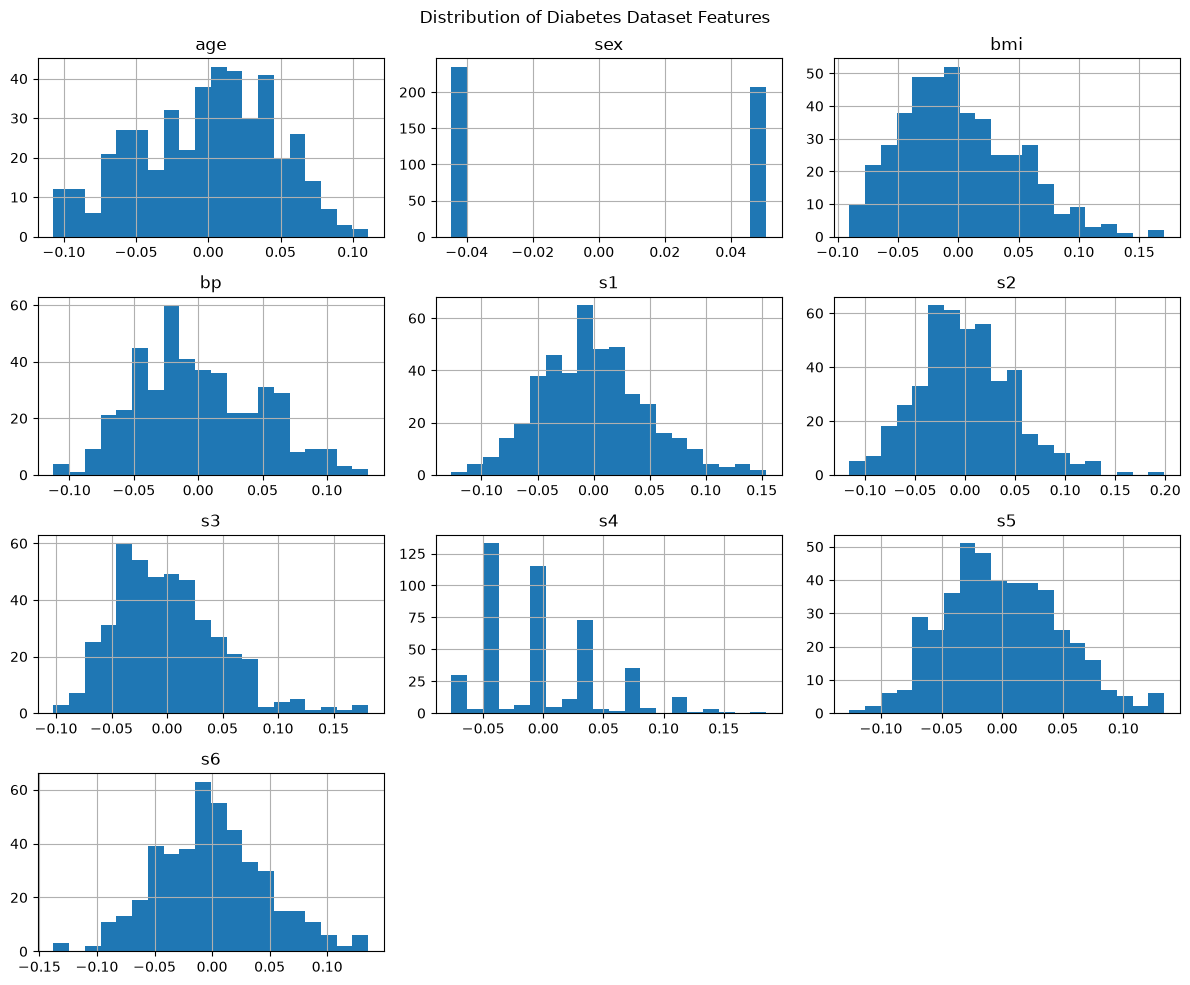

In [5]:
X.hist(
    figsize=(12, 10),
    bins=20
)

plt.suptitle("Distribution of Diabetes Dataset Features")
plt.tight_layout()
plt.show()

## Data Cleaning

The dataset was checked for missing values. The number of missing values was calculated for each feature before continuing with the regression analysis.

## Step 2: Linear Regression

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Use BMI as the single independent variable
X_simple = X[["bmi"]]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_simple,
    y,
    test_size=0.20,
    random_state=42
)

# Create and train the model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Make predictions
y_pred_linear = linear_model.predict(X_test)

# Calculate evaluation metrics
mae_linear = mean_absolute_error(y_test, y_pred_linear)
mse_linear = mean_squared_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(mse_linear)
r2_linear = r2_score(y_test, y_pred_linear)

# Display results
print("Simple Linear Regression Results")
print("--------------------------------")
print("MAE:", mae_linear)
print("MSE:", mse_linear)
print("RMSE:", rmse_linear)
print("R²:", r2_linear)

Simple Linear Regression Results
--------------------------------
MAE: 52.25997644534553
MSE: 4061.8259284949268
RMSE: 63.73245584860925
R²: 0.23335039815872138


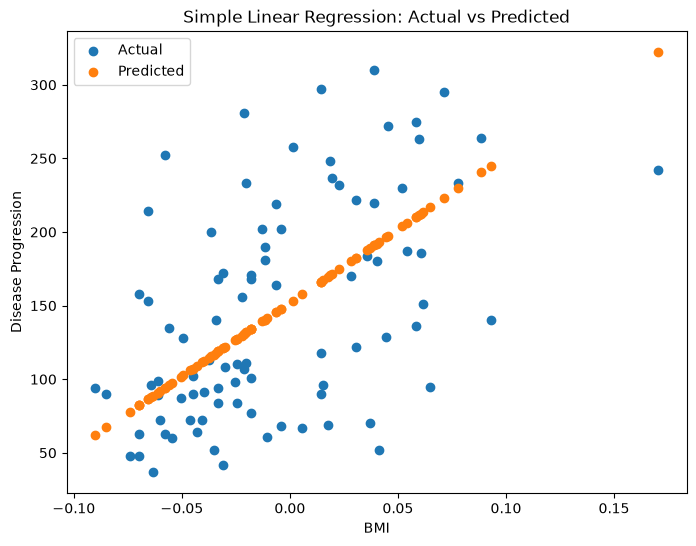

In [7]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_test["bmi"],
    y_test,
    label="Actual"
)

plt.scatter(
    X_test["bmi"],
    y_pred_linear,
    label="Predicted"
)

plt.xlabel("BMI")
plt.ylabel("Disease Progression")
plt.title("Simple Linear Regression: Actual vs Predicted")
plt.legend()
plt.show()

## Step 3: Multiple Regression

In [8]:
# Multiple Regression using all independent variables

X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Create the Multiple Regression model
multiple_model = LinearRegression()

# Train the model
multiple_model.fit(X_train_multi, y_train_multi)

# Predict target values
y_pred_multiple = multiple_model.predict(X_test_multi)

# Calculate evaluation metrics
mae_multiple = mean_absolute_error(
    y_test_multi,
    y_pred_multiple
)

mse_multiple = mean_squared_error(
    y_test_multi,
    y_pred_multiple
)

rmse_multiple = np.sqrt(mse_multiple)

r2_multiple = r2_score(
    y_test_multi,
    y_pred_multiple
)

# Display results
print("Multiple Regression Results")
print("---------------------------")
print("MAE:", mae_multiple)
print("MSE:", mse_multiple)
print("RMSE:", rmse_multiple)
print("R²:", r2_multiple)

Multiple Regression Results
---------------------------
MAE: 42.79409467959994
MSE: 2900.1936284934814
RMSE: 53.85344583676593
R²: 0.4526027629719195


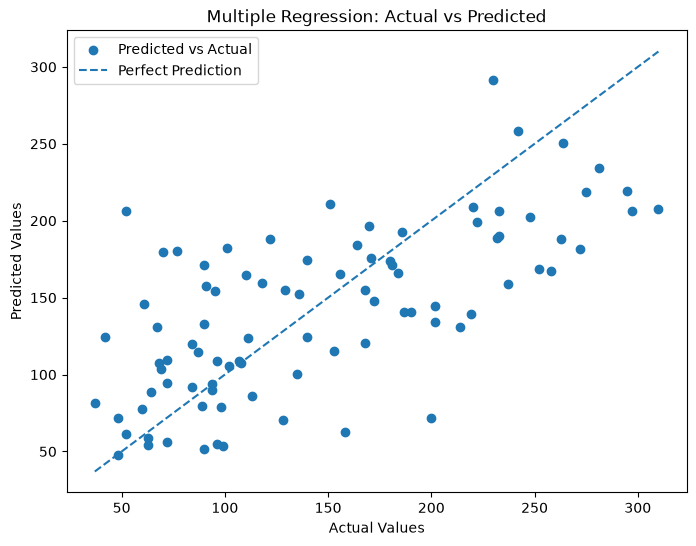

In [9]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_multi,
    y_pred_multiple,
    label="Predicted vs Actual"
)

plt.plot(
    [y_test_multi.min(), y_test_multi.max()],
    [y_test_multi.min(), y_test_multi.max()],
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Multiple Regression: Actual vs Predicted")
plt.legend()
plt.show()

## Step 4: Polynomial Regression

In [10]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

# Use BMI as the independent variable
X_poly = X[["bmi"]]

# Split the data into training and testing sets
X_train_poly, X_test_poly, y_train_poly, y_test_poly = train_test_split(
    X_poly,
    y,
    test_size=0.20,
    random_state=42
)

# Test different polynomial degrees
degrees = [1, 2, 3, 4, 5]

polynomial_results = []

for degree in degrees:

    if degree == 1:
        poly_model = LinearRegression()
    else:
        poly_model = make_pipeline(
            PolynomialFeatures(degree=degree),
            LinearRegression()
        )

    poly_model.fit(X_train_poly, y_train_poly)

    y_pred_poly = poly_model.predict(X_test_poly)

    mae = mean_absolute_error(y_test_poly, y_pred_poly)
    mse = mean_squared_error(y_test_poly, y_pred_poly)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test_poly, y_pred_poly)

    polynomial_results.append([
        degree,
        mae,
        mse,
        rmse,
        r2
    ])

polynomial_results_df = pd.DataFrame(
    polynomial_results,
    columns=["Degree", "MAE", "MSE", "RMSE", "R²"]
)

display(polynomial_results_df)

,Degree,MAE,MSE,RMSE,R²
0,1,52.259976,4061.825928,63.732456,0.233350
1,2,52.383912,4085.025481,63.914204,0.228972
2,3,52.181400,4064.443384,63.752987,0.232856
3,4,52.376339,4226.144878,65.008806,0.202336
4,5,51.884611,4085.845567,63.920619,0.228817


In [11]:
comparison_results = pd.DataFrame({
    "Model": [
        "Simple Linear Regression",
        "Multiple Regression"
    ],
    "MAE": [
        mae_linear,
        mae_multiple
    ],
    "MSE": [
        mse_linear,
        mse_multiple
    ],
    "RMSE": [
        rmse_linear,
        rmse_multiple
    ],
    "R²": [
        r2_linear,
        r2_multiple
    ]
})

print("Linear and Multiple Regression Results")
display(comparison_results)

print("Polynomial Regression Results")
display(polynomial_results_df)

Linear and Multiple Regression Results


,Model,MAE,MSE,RMSE,R²
0,Simple Linear Regression,52.259976,4061.825928,63.732456,0.233350
1,Multiple Regression,42.794095,2900.193628,53.853446,0.452603


Polynomial Regression Results


,Degree,MAE,MSE,RMSE,R²
0,1,52.259976,4061.825928,63.732456,0.233350
1,2,52.383912,4085.025481,63.914204,0.228972
2,3,52.181400,4064.443384,63.752987,0.232856
3,4,52.376339,4226.144878,65.008806,0.202336
4,5,51.884611,4085.845567,63.920619,0.228817


C:\Users\HP\AppData\Roaming\Python\Python311\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
C:\Users\HP\AppData\Roaming\Python\Python311\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
C:\Users\HP\AppData\Roaming\Python\Python311\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
C:\Users\HP\AppData\Roaming\Python\Python311\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


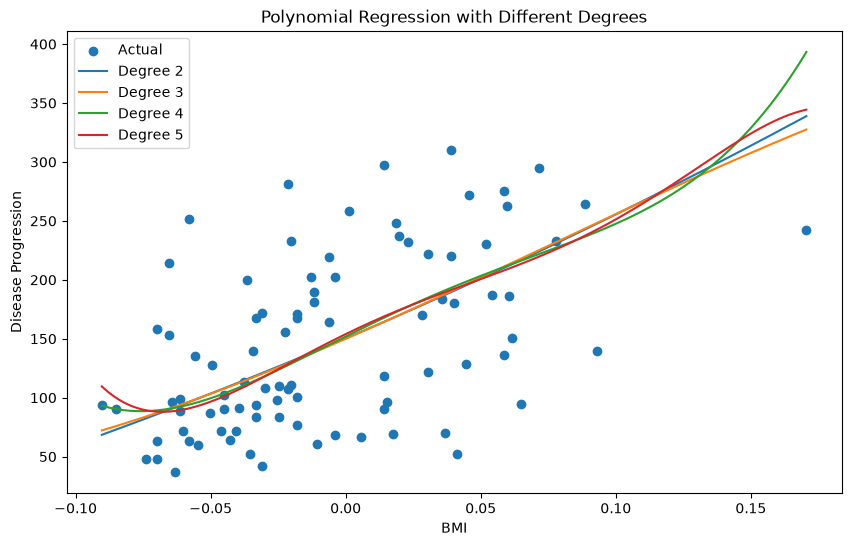

In [12]:
plt.figure(figsize=(10, 6))

plt.scatter(
    X_test_poly["bmi"],
    y_test_poly,
    label="Actual"
)

x_range = np.linspace(
    X_poly["bmi"].min(),
    X_poly["bmi"].max(),
    200
).reshape(-1, 1)

for degree in [2, 3, 4, 5]:

    poly_model = make_pipeline(
        PolynomialFeatures(degree=degree),
        LinearRegression()
    )

    poly_model.fit(X_train_poly, y_train_poly)

    predictions = poly_model.predict(x_range)

    plt.plot(
        x_range,
        predictions,
        label=f"Degree {degree}"
    )

plt.xlabel("BMI")
plt.ylabel("Disease Progression")
plt.title("Polynomial Regression with Different Degrees")
plt.legend()
plt.show()

### Polynomial Degree and Model Fit

The polynomial regression models were tested using increasing polynomial degrees. Lower-degree models may underfit the relationship between BMI and disease progression, while higher-degree models provide greater flexibility and may increase the risk of overfitting. The MAE, MSE, RMSE, and R² values are compared across the different degrees to evaluate their performance.

## Step 5: Regularization with Ridge and Lasso Regression

In [13]:
from sklearn.linear_model import Ridge

alphas = [0.01, 0.1, 1, 10, 100]

ridge_results = []

for alpha in alphas:
    
    ridge_model = Ridge(alpha=alpha)
    
    ridge_model.fit(
        X_train_multi,
        y_train_multi
    )
    
    y_pred_ridge = ridge_model.predict(
        X_test_multi
    )
    
    mae = mean_absolute_error(
        y_test_multi,
        y_pred_ridge
    )
    
    mse = mean_squared_error(
        y_test_multi,
        y_pred_ridge
    )
    
    rmse = np.sqrt(mse)
    
    r2 = r2_score(
        y_test_multi,
        y_pred_ridge
    )
    
    ridge_results.append([
        alpha,
        mae,
        mse,
        rmse,
        r2
    ])

ridge_results_df = pd.DataFrame(
    ridge_results,
    columns=["Alpha", "MAE", "MSE", "RMSE", "R²"]
)

print("Ridge Regression Results")
display(ridge_results_df)

Ridge Regression Results


,Alpha,MAE,MSE,RMSE,R²
0,0.01,42.836888,2882.290180,53.686965,0.455982
1,0.10,42.996932,2856.486888,53.446112,0.460852
2,1.00,46.138858,3077.415939,55.474462,0.419153
3,10.00,58.030756,4443.952637,66.662978,0.161226
4,100.00,63.239467,5233.663687,72.344065,0.012172


In [14]:
from sklearn.linear_model import Lasso

lasso_results = []

for alpha in alphas:
    
    lasso_model = Lasso(
        alpha=alpha,
        max_iter=10000
    )
    
    lasso_model.fit(
        X_train_multi,
        y_train_multi
    )
    
    y_pred_lasso = lasso_model.predict(
        X_test_multi
    )
    
    mae = mean_absolute_error(
        y_test_multi,
        y_pred_lasso
    )
    
    mse = mean_squared_error(
        y_test_multi,
        y_pred_lasso
    )
    
    rmse = np.sqrt(mse)
    
    r2 = r2_score(
        y_test_multi,
        y_pred_lasso
    )
    
    lasso_results.append([
        alpha,
        mae,
        mse,
        rmse,
        r2
    ])

lasso_results_df = pd.DataFrame(
    lasso_results,
    columns=["Alpha", "MAE", "MSE", "RMSE", "R²"]
)

print("Lasso Regression Results")
display(lasso_results_df)

Lasso Regression Results


,Alpha,MAE,MSE,RMSE,R²
0,0.01,42.831847,2878.559386,53.652208,0.456686
1,0.10,42.854428,2798.193485,52.897954,0.471855
2,1.00,49.730328,3403.575722,58.340172,0.357592
3,10.00,64.006461,5361.533457,73.222493,-0.011963
4,100.00,64.006461,5361.533457,73.222493,-0.011963


In [15]:
print("Ridge Regression Results")
display(ridge_results_df)

print("Lasso Regression Results")
display(lasso_results_df)

Ridge Regression Results


,Alpha,MAE,MSE,RMSE,R²
0,0.01,42.836888,2882.290180,53.686965,0.455982
1,0.10,42.996932,2856.486888,53.446112,0.460852
2,1.00,46.138858,3077.415939,55.474462,0.419153
3,10.00,58.030756,4443.952637,66.662978,0.161226
4,100.00,63.239467,5233.663687,72.344065,0.012172


Lasso Regression Results


,Alpha,MAE,MSE,RMSE,R²
0,0.01,42.831847,2878.559386,53.652208,0.456686
1,0.10,42.854428,2798.193485,52.897954,0.471855
2,1.00,49.730328,3403.575722,58.340172,0.357592
3,10.00,64.006461,5361.533457,73.222493,-0.011963
4,100.00,64.006461,5361.533457,73.222493,-0.011963


In [16]:
best_ridge_alpha = ridge_results_df.loc[
    ridge_results_df["R²"].idxmax(),
    "Alpha"
]

best_lasso_alpha = lasso_results_df.loc[
    lasso_results_df["R²"].idxmax(),
    "Alpha"
]

print("Best Ridge Alpha:", best_ridge_alpha)
print("Best Lasso Alpha:", best_lasso_alpha)

Best Ridge Alpha: 0.1
Best Lasso Alpha: 0.1


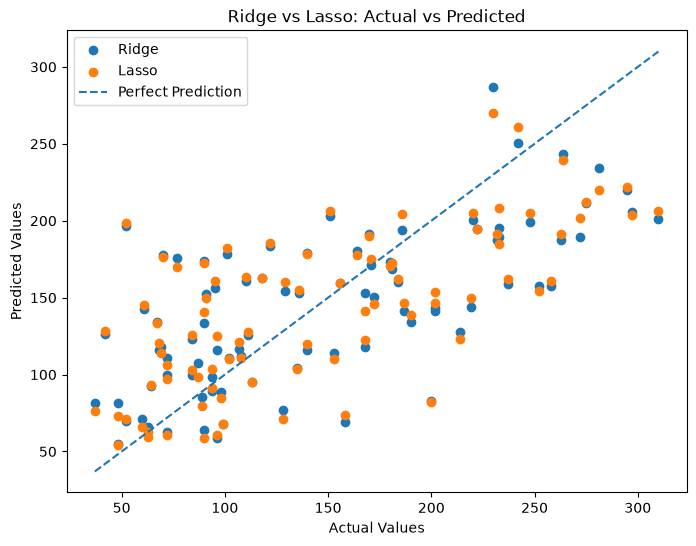

In [17]:
best_ridge_model = Ridge(
    alpha=best_ridge_alpha
)

best_ridge_model.fit(
    X_train_multi,
    y_train_multi
)

best_ridge_pred = best_ridge_model.predict(
    X_test_multi
)


best_lasso_model = Lasso(
    alpha=best_lasso_alpha,
    max_iter=10000
)

best_lasso_model.fit(
    X_train_multi,
    y_train_multi
)

best_lasso_pred = best_lasso_model.predict(
    X_test_multi
)


plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_multi,
    best_ridge_pred,
    label="Ridge"
)

plt.scatter(
    y_test_multi,
    best_lasso_pred,
    label="Lasso"
)

plt.plot(
    [y_test_multi.min(), y_test_multi.max()],
    [y_test_multi.min(), y_test_multi.max()],
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Ridge vs Lasso: Actual vs Predicted")
plt.legend()
plt.show()

### Effect of Alpha Values

The alpha parameter controls the strength of regularization. Smaller alpha values apply weaker regularization, while larger alpha values apply stronger regularization. Ridge regression reduces the size of model coefficients, while Lasso regression can reduce some coefficients toward zero. The results for different alpha values were compared using MAE, MSE, RMSE, and R² to determine how regularization affected model performance.

## Step 6: Model Comparison and Analysis

In [18]:
comparison_all = pd.DataFrame({
    "Model": [
        "Simple Linear Regression",
        "Multiple Regression",
        "Polynomial Regression Degree 2",
        "Polynomial Regression Degree 3",
        "Polynomial Regression Degree 4",
        "Polynomial Regression Degree 5",
        "Ridge Regression (α=0.10)",
        "Lasso Regression (α=0.10)"
    ],
    "MAE": [
        mae_linear,
        mae_multiple,
        polynomial_results_df.loc[1, "MAE"],
        polynomial_results_df.loc[2, "MAE"],
        polynomial_results_df.loc[3, "MAE"],
        polynomial_results_df.loc[4, "MAE"],
        ridge_results_df.loc[1, "MAE"],
        lasso_results_df.loc[1, "MAE"]
    ],
    "MSE": [
        mse_linear,
        mse_multiple,
        polynomial_results_df.loc[1, "MSE"],
        polynomial_results_df.loc[2, "MSE"],
        polynomial_results_df.loc[3, "MSE"],
        polynomial_results_df.loc[4, "MSE"],
        ridge_results_df.loc[1, "MSE"],
        lasso_results_df.loc[1, "MSE"]
    ],
    "RMSE": [
        rmse_linear,
        rmse_multiple,
        polynomial_results_df.loc[1, "RMSE"],
        polynomial_results_df.loc[2, "RMSE"],
        polynomial_results_df.loc[3, "RMSE"],
        polynomial_results_df.loc[4, "RMSE"],
        ridge_results_df.loc[1, "RMSE"],
        lasso_results_df.loc[1, "RMSE"]
    ],
    "R²": [
        r2_linear,
        r2_multiple,
        polynomial_results_df.loc[1, "R²"],
        polynomial_results_df.loc[2, "R²"],
        polynomial_results_df.loc[3, "R²"],
        polynomial_results_df.loc[4, "R²"],
        ridge_results_df.loc[1, "R²"],
        lasso_results_df.loc[1, "R²"]
    ]
})

display(comparison_all)

,Model,MAE,MSE,RMSE,R²
0,Simple Linear Regression,52.259976,4061.825928,63.732456,0.233350
1,Multiple Regression,42.794095,2900.193628,53.853446,0.452603
2,Polynomial Regression Degree 2,52.383912,4085.025481,63.914204,0.228972
3,Polynomial Regression Degree 3,52.181400,4064.443384,63.752987,0.232856
4,Polynomial Regression Degree 4,52.376339,4226.144878,65.008806,0.202336
5,Polynomial Regression Degree 5,51.884611,4085.845567,63.920619,0.228817
6,Ridge Regression (α=0.10),42.996932,2856.486888,53.446112,0.460852
7,Lasso Regression (α=0.10),42.854428,2798.193485,52.897954,0.471855


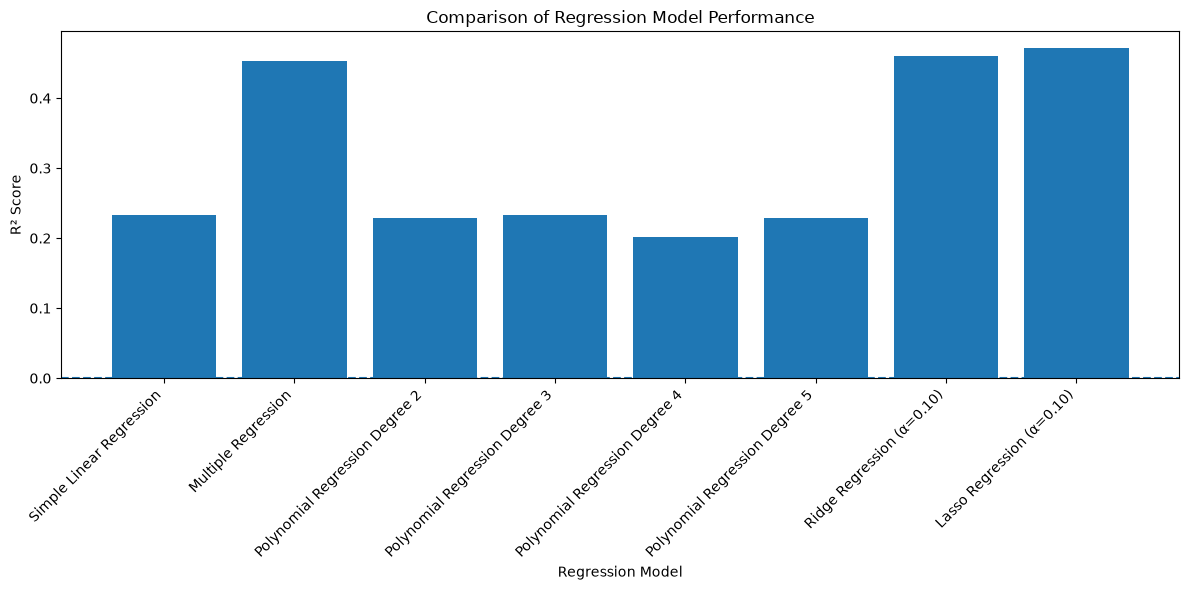

In [19]:
plt.figure(figsize=(12, 6))

plt.bar(
    comparison_all["Model"],
    comparison_all["R²"]
)

plt.xlabel("Regression Model")
plt.ylabel("R² Score")
plt.title("Comparison of Regression Model Performance")
plt.xticks(rotation=45, ha="right")
plt.axhline(0, linestyle="--")
plt.tight_layout()
plt.show()

### Model Comparison and Analysis

The regression models produced different levels of predictive performance on the Diabetes dataset. Simple Linear Regression using BMI produced an R² of approximately 0.2333, indicating that BMI alone explained a relatively limited portion of the variation in the target variable. Multiple Regression performed substantially better, with an R² of approximately 0.4526 and a lower RMSE of approximately 53.85. This indicates that using multiple independent variables provided more useful information for predicting disease progression than using BMI alone.

The Polynomial Regression models did not substantially improve performance over Simple Linear Regression. Degrees 2 through 5 produced R² values of approximately 0.2290, 0.2329, 0.2023, and 0.2288, respectively. The results demonstrate that increasing polynomial complexity did not consistently improve prediction on the test data. In particular, the degree 4 model had the lowest R² among the polynomial models tested, showing that increasing model complexity does not necessarily lead to better generalization.

Regularization produced the strongest results. Ridge Regression performed best at an alpha of 0.10, producing an R² of approximately 0.4609 and an RMSE of approximately 53.45. Lasso Regression also performed best at an alpha of 0.10 and achieved the highest R² of approximately 0.4719, together with the lowest MSE of approximately 2798.19 and RMSE of approximately 52.90 among the models compared. These results indicate that moderate regularization improved predictive performance compared with the unregularized Multiple Regression model.

The alpha results also demonstrate the effect of excessive regularization. Larger alpha values substantially reduced the performance of both Ridge and Lasso models. Therefore, the results suggest that moderate regularization helped control model complexity, whereas very strong regularization caused underfitting. Overall, Lasso Regression with alpha = 0.10 produced the strongest test-set performance among the models evaluated.

### Insights from the Diabetes Dataset

The analysis shows that disease progression is influenced by information contained across multiple features rather than by BMI alone. The Multiple Regression model substantially improved over the Simple Linear Regression model, demonstrating the value of using several predictors. The polynomial experiments showed that adding nonlinear complexity to the BMI relationship alone did not provide a consistent improvement in test-set performance.

The regularization results provide an additional insight into the dataset. A moderate alpha value of 0.10 produced better results than the larger alpha values tested for both Ridge and Lasso regression. Lasso Regression achieved the strongest overall performance in this analysis, suggesting that regularization was useful for controlling model complexity while maintaining predictive information from the available features.